# Aula 22 — Rapidly-exploring Random Trees — RRT

**ECAA08 — Arquitetura de Sistemas SCADA | Grupo 06**  
**Integrantes:** Arthur, Caique, Luis Felipe e Marina  
**Planta:** Sistema SCADA aplicado a um Drone Agrícola de Pulverização  
**Etapa 3:** Árvores — planejamento e execução supervisionada de missões de pulverização


## 1. Contexto e objetivo no SCADA

O operador solicita no SCADA um deslocamento da posição atual à entrada de um talhão. O servidor calcula uma proposta geométrica que contorna obstáculos conhecidos, apresenta-a no mapa e registra o resultado do planejamento. A posição inicial do exemplo é BASE e o destino é T1.

O caminho é uma informação para execução supervisionada. Não representa a cobertura completa do talhão nem libera a bomba durante o deslocamento. Esta aula trata o drone como unidade móvel, preservando a aplicação agrícola.

## 2. Modelo e fundamentação

RRT começa na posição inicial e amostra configurações no plano. Escolhe o nó mais próximo e estende a árvore por um passo limitado. Se $a$ é o nó escolhido e $q$ a amostra:

$$q_{novo}=a+\min(1,\eta/\|q-a\|)(q-a),$$

com passo $\eta=10$ m. O viés de amostragem para o destino é 0,12 e o orçamento padrão é 2.500 iterações. Uma aresta só é inserida se todo o segmento estiver livre. Pais sempre têm índices menores que seus filhos; por isso não há ciclos.

O corpo é representado por um disco ilustrativo de raio 0,6 m com folga de 1,4 m. A inflação retangular dos obstáculos é conservadora nos cantos em relação ao disco exato. Não se infere o tamanho real do drone. O planejador é 2D: obstáculos são interdições verticais e a altitude é assumida adequada. Busca linear de vizinho leva a um limite de $O(K^2+KO)$ para $K$ iterações e $O$ obstáculos.

## 3. Procedimento e demonstração

1. Verificar que o segmento direto BASE–T1 é interditado.
2. Executar a busca com semente 22 e mostrar três estágios de crescimento.
3. Extrair o caminho pelos pais e somar seus segmentos.
4. Verificar colisões por um segundo método geométrico: orientações contra os lados dos retângulos.
5. Repetir com dez sementes e com barreira total, início inválido e orçamento zero.

Pergunta para a apresentação: o esgotamento de iterações prova que não existe caminho? Não; é um resultado limitado ao orçamento da busca.

## 4. Experimentos executáveis

Execute as células em ordem, com a pasta `Arquivos_de_Apoio` ao lado do notebook. Os algoritmos centrais aparecem abaixo; dados, funções comuns e verificações estão nos arquivos de apoio. Não há download de dados durante a execução.

In [1]:
from pathlib import Path
import sys
# Funciona na pasta da etapa, na raiz do repositório ou em uma subpasta da etapa.
origem = Path.cwd().resolve()
candidatos = [p / sufixo for p in [origem, *origem.parents]
              for sufixo in (Path('.'), Path('etapa-03-arvores'))]
ETAPA = next((p for p in candidatos if (p/'Arquivos_de_Apoio'/'scada_arvores.py').is_file()), None)
if ETAPA is None:
    raise FileNotFoundError('Extraia o pacote completo e abra o notebook na pasta etapa-03-arvores.')
sys.path.insert(0, str(ETAPA/'Arquivos_de_Apoio'))
from scada_arvores import *
import scada_arvores as core
import visualizacao as vis
from verificacoes import TESTES, conferir_rrt
import matplotlib.pyplot as plt
import json
print('Sistema SCADA do Drone Agrícola | Grupo 06 | simulação acadêmica')


Sistema SCADA do Drone Agrícola | Grupo 06 | simulação acadêmica


In [2]:
def rrt(inicio, fim, seed=22, max_iter=2500, passo=10.0, obstaculos=OBSTACULOS):
    if passo <= 0 or not math.isfinite(passo) or type(max_iter) is not int or max_iter < 0:
        raise ValueError('Parâmetros de busca inválidos')
    inicio, fim = tuple(inicio), tuple(fim)
    if not livre(inicio, obstaculos) or not livre(fim, obstaculos):
        return dict(status='PONTO_INVALIDO', nos=[], pais=[], caminho=[], iteracoes=0)
    nos = [inicio]; pais = [None]; rng = random.Random(seed)
    def resultado(status, it, ultimo=None):
        caminho = []
        while ultimo is not None: caminho.append(nos[ultimo]); ultimo = pais[ultimo]
        return dict(status=status, nos=nos, pais=pais, caminho=caminho[::-1], iteracoes=it)
    if inicio == fim: return resultado('SUCESSO', 0, 0)
    x0, x1, y0, y1 = LIMITES
    for it in range(1, max_iter+1):
        alvo = fim if rng.random() < .12 else (rng.uniform(x0+MARGEM, x1-MARGEM), rng.uniform(y0+MARGEM, y1-MARGEM))
        if not livre(alvo, obstaculos): continue
        pai = min(range(len(nos)), key=lambda i: (math.dist(nos[i], alvo), i))
        a = nos[pai]; d = math.dist(a, alvo)
        if d < 1e-12: continue
        b = alvo if d <= passo else tuple(a[k]+passo*(alvo[k]-a[k])/d for k in range(2))
        if not segmento_livre(a, b, obstaculos): continue
        nos.append(b); pais.append(pai)
        if b == fim: return resultado('SUCESSO', it, len(nos)-1)
        if math.dist(b, fim) <= passo and segmento_livre(b, fim, obstaculos):
            pais.append(len(nos)-1); nos.append(fim)
            return resultado('SUCESSO', it, len(nos)-1)
    return resultado('ORCAMENTO_ESGOTADO', max_iter)


### Planejamento e crescimento

SUCESSO | iterações: 150 | nós: 100
Comprimento: 383.443 m


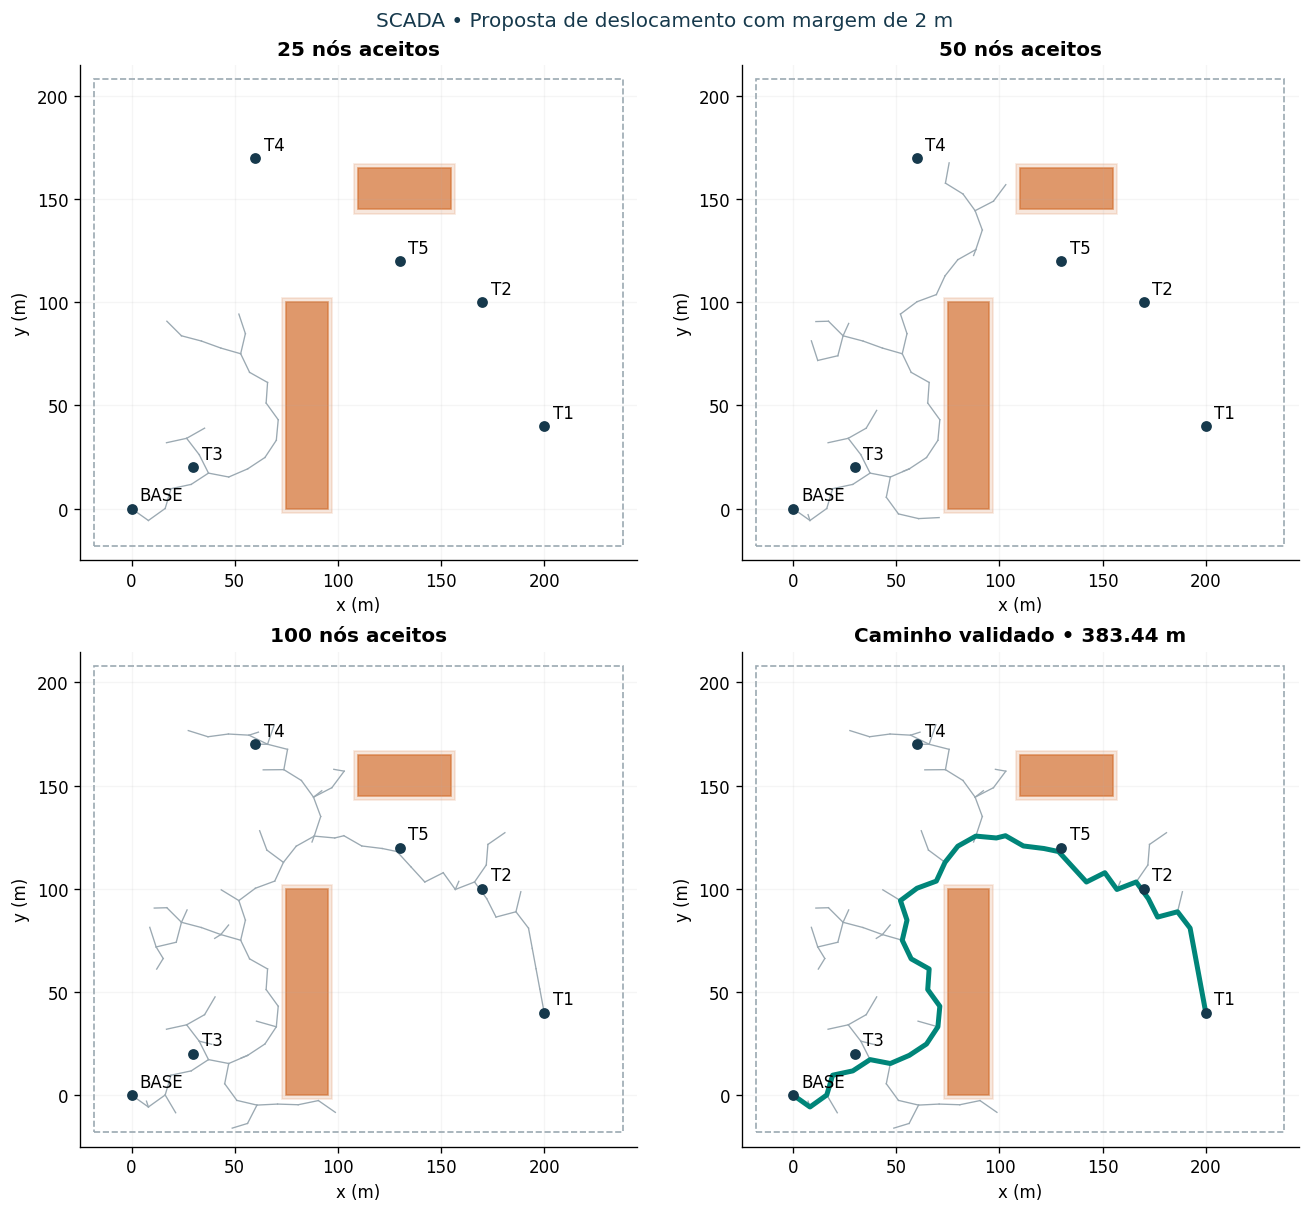

In [3]:
res=rrt(PONTOS['BASE'],PONTOS['T1'])
conferir_rrt(res)
print(res['status'], '| iterações:',res['iteracoes'],'| nós:',len(res['nos']))
print('Comprimento:',round(comprimento(res['caminho']),3),'m')
vis.figura22(res);plt.show()

### Variabilidade entre dez sementes

In [4]:
sucessos=[]
for seed in range(10):
    r=rrt(PONTOS['BASE'],PONTOS['T1'],seed=seed);conferir_rrt(r)
    d=comprimento(r['caminho']) if r['caminho'] else None
    print(seed,r['status'],r['iteracoes'],None if d is None else round(d,3))
    if d is not None:sucessos.append(d)
print('Sucessos:',len(sucessos),'/ 10')

0 SUCESSO 134 358.444
1 SUCESSO 158 391.369
2 SUCESSO 123 356.713
3 SUCESSO 119 367.185
4 SUCESSO 88 331.066
5 SUCESSO 184 407.516
6 SUCESSO 188 416.099
7 SUCESSO 125 399.164
8 SUCESSO 132 395.068
9 SUCESSO 121 391.166
Sucessos: 10 / 10


### Verificação e resultados de referência

As verificações confrontam propriedades, referências independentes e casos de fronteira. Consulte `Arquivos_de_Apoio/verificacoes.py` para os critérios completos.

In [5]:
RESUMO = TESTES[22]()
print(json.dumps(RESUMO, ensure_ascii=False, indent=2))
print('Verificações da aula 22: APROVADAS')

{
  "nos": 100,
  "iteracoes": 150,
  "comprimento_m": 383.4433377597177
}
Verificações da aula 22: APROVADAS


## 5. Interpretação, limites e continuidade

O RRT básico retorna o primeiro caminho encontrado e não garante ótimo global. Não foram modelados vento, dinâmica, consumo energético, velocidade de execução ou cobertura agrícola. A margem é geométrica e não certificação de operação. Posição confiável e permissivos continuam necessários.

Na Aula 26, KD-Trees são estudadas separadamente como índice espacial. Esta implementação do RRT mantém busca linear, de forma explícita. Na Aula 28, os caminhos de ida e retorno são validados antes das confirmações simuladas de fase.

## 6. Referências

- [LaValle — About RRTs](https://lavalle.pl/rrt/about.html).
- [LaValle — Planning Algorithms](https://lavalle.pl/planning/).